<a href="https://colab.research.google.com/github/HinnaNayab/DeepLearning/blob/Applied-AI/Tutorial_8A_object_detection_pre_trained_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#importing libraries
import tensorflow as tf
import tensorflow_hub as hub
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os
from PIL import Image

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [3]:
#Loading Pre-trained Faster-RCNN model
MODEL_URL = "https://tfhub.dev/tensorflow/faster_rcnn/resnet50_v1_640x640/1"
model = hub.load(MODEL_URL)

#Pre-trained model uses COCO dataset; following are the class labels of that dataset
COCO_CLASSES = {
    1: "person", 2: "bicycle", 3: "car", 4: "motorcycle",
    5: "airplane", 6: "bus", 7: "train", 8: "truck",
    9: "boat", 10: "traffic light", 11: "fire hydrant",
    13: "stop sign", 14: "parking meter", 15: "bench",
    16: "bird", 17: "cat", 18: "dog", 19: "horse",
    20: "sheep", 21: "cow", 22: "elephant", 23: "bear",
    24: "zebra", 25: "giraffe", 27: "backpack",
    28: "umbrella", 31: "handbag", 32: "tie",
    33: "suitcase", 34: "frisbee", 35: "skis",
    36: "snowboard", 37: "sports ball", 38: "kite",
    39: "baseball bat", 40: "baseball glove",
    41: "skateboard", 42: "surfboard", 43: "tennis racket",
    44: "bottle", 46: "wine glass", 47: "cup",
    48: "fork", 49: "knife", 50: "spoon", 51: "bowl",
    52: "banana", 53: "apple", 54: "sandwich",
    55: "orange", 56: "broccoli", 57: "carrot",
    58: "hot dog", 59: "pizza", 60: "donut", 61: "cake",
    62: "chair", 63: "couch", 64: "potted plant",
    65: "bed", 67: "dining table", 70: "toilet",
    72: "TV", 73: "laptop", 74: "mouse", 75: "remote",
    76: "keyboard", 77: "cell phone", 78: "microwave",
    79: "oven", 80: "toaster", 81: "sink",
    82: "refrigerator", 84: "book", 85: "clock",
    86: "vase", 87: "scissors", 88: "teddy bear",
    89: "hair drier", 90: "toothbrush"
}

In [4]:
#Function for performing object detection
def detect_objects(image_path, model, threshold=0.5):
    # Debug message to verify the file path
    print(f"Loading image from: {image_path}")

    # Load the image
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(f"Could not load image at {image_path}. Please check the file path.")

    # Convert to RGB format for visualization and TensorFlow processing
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Resize image to the model's expected input size
    input_tensor = tf.convert_to_tensor(image_rgb, dtype=tf.uint8)
    input_tensor = input_tensor[tf.newaxis, ...]  # Add batch dimension

    # Run object detection
    detections = model(input_tensor)

    # Extract detection results
    boxes = detections['detection_boxes'][0].numpy()  # Bounding boxes
    #class_indices = detections['detection_classes'][0].numpy().astype(int) - 1  # Class indices, -1 to adjust for zero-indexed
    class_indices = detections['detection_classes'][0].numpy().astype(int) #removed -1 to adjust for the class labels IDs
    scores = detections['detection_scores'][0].numpy()  # Confidence scores

    # Filter out detections below the confidence threshold
    valid_detections = scores >= threshold
    boxes = boxes[valid_detections]
    class_indices = class_indices[valid_detections]
    scores = scores[valid_detections]

    return image_rgb, boxes, class_indices, scores

In [5]:
# Function to display the image with detected bounding boxes
def display_image_with_detections(image, boxes, class_indices, scores, threshold=0.5):
    height, width, _ = image.shape
    for i, box in enumerate(boxes):
        if scores[i] >= threshold:
            ymin, xmin, ymax, xmax = box
            (left, right, top, bottom) = (int(xmin * width), int(xmax * width), int(ymin * height), int(ymax * height))

            # Draw bounding box
            cv2.rectangle(image, (left, top), (right, bottom), (0, 255, 0), 2)

            # Display label and confidence
            #label = f"{COCO_CLASSES[class_indices[i]]}: {scores[i]:.2f}"
            label = f"{COCO_CLASSES.get(class_indices[i], 'Unknown')}: {scores[i]:.2f}" #using the model's original label category with original IDs
            cv2.putText(image, label, (left, top - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Show the result with matplotlib
    plt.figure(figsize=(12, 8))
    plt.imshow(image)
    plt.axis('off')
    plt.show()

Loading image from: /content/bears.jpeg


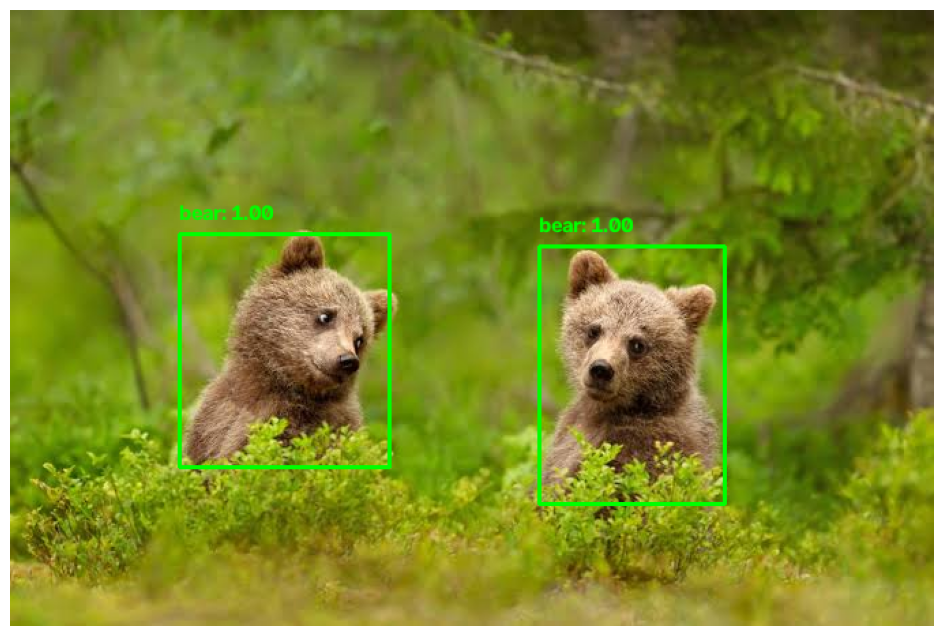

In [7]:
# Example usage with your image path
image_path = r"/content/bears.jpeg"
try:
    image_rgb, detected_boxes, detected_classes, detected_scores = detect_objects(image_path, model, threshold=0.5)
    display_image_with_detections(image_rgb, detected_boxes, detected_classes, detected_scores)
except FileNotFoundError as e:
    print(e)

Need to figure out why the predict oject detected is worng (model was predicting "zebra" for the bear in above image with 100% confidence), chatgpt says the mapping of object IDs with class labels in COCO dataset need to be mentioned explicitly. so maybe need to add IDs with each class label.

The probem was in "class-label mapping,", this line in Sir's code:
class_indices = detections['detection_classes'][0].numpy().astype(int) - 1               
It subtracts 1 from the model's class ID and then uses that number to look up a label in COCO_CLASSES.

However, the COCO dataset uses category IDs that are not all consecutive. Sir's tutorial list contains 80 labels in a consecutive list, whereas the model can return the original COCO category IDs. As a result, the code can display the wrong animal name.    

For example, the COCO category ID for a bear is 23, and for a zebra it is 24. The original COCO IDs must be mapped correctly to their names.

To fix that, we keep the same pretrained Faster R-CNN model and change only how its class IDs are interpreted.
So, we replaced the class-label list with different mapping (with IDs, see section where we load pre-trained model). These are the COCO category IDs and their corresponding labels.

In [9]:
# Example usage with another image
#image_path = r"/content/airplane.jpeg"
#try:
#    image_rgb, detected_boxes, detected_classes, detected_scores = detect_objects(image_path, model, threshold=0.5)
#   display_image_with_detections(image_rgb, detected_boxes, detected_classes, detected_scores)
#except FileNotFoundError as e:
#    print(e)

Loading image from: /content/bears.jpeg
Faster R-CNN ResNet101


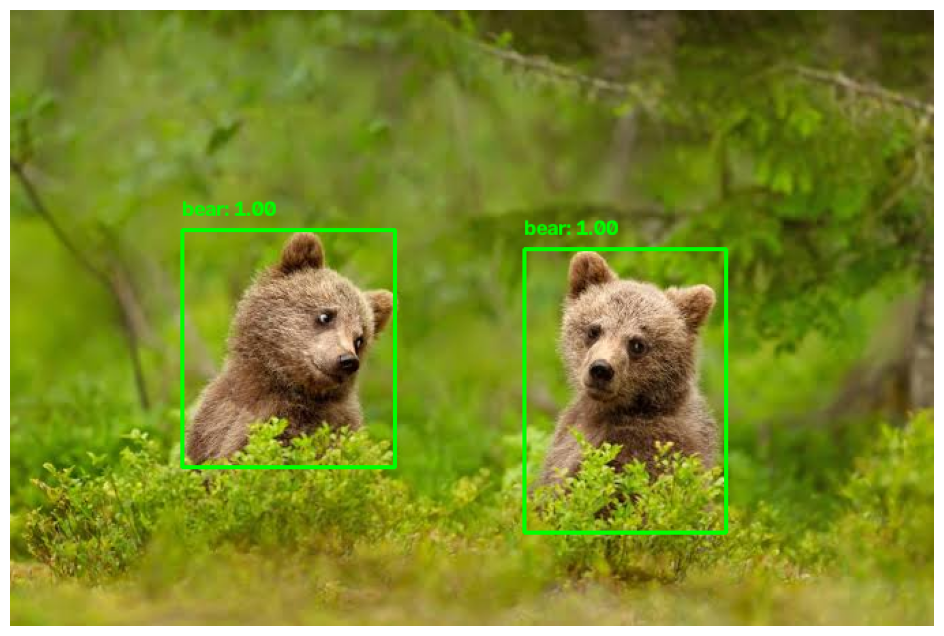

Loading image from: /content/bears.jpeg
SSD MobileNet V2


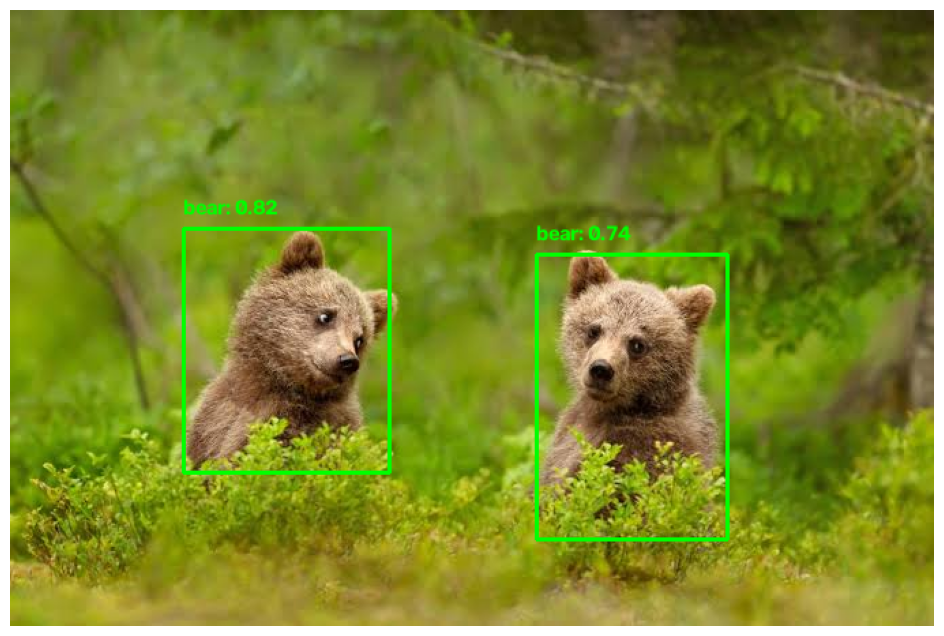

In [11]:
#task 1.2:
#using different models with different backbones
#Sir's tutorial used Faster R-CNN with a ResNet50 backbone.
#A backbone is the part of the model that extracts visual features, such as edges, shapes, and textures, from an image.

#Test 1 with "Faster R-CNN ResNet101": Deeper Feature extraction network
#Test 2 with "SSD MobileNet V2": Lightweight model: Faster and more computationally efficient (Maybe comapre computation time for all 3 too?)


# Model 1: Faster R-CNN with ResNet101 backbone
model_resnet101 = hub.load(
    "https://tfhub.dev/tensorflow/faster_rcnn/resnet101_v1_640x640/1"
)

# Model 2: SSD with MobileNet V2 backbone
model_mobilenet = hub.load(
    "https://tfhub.dev/tensorflow/ssd_mobilenet_v2/2"
)
image_path = r"/content/bears.jpeg"
# Test Faster R-CNN ResNet101
image_rgb, boxes, classes, scores = detect_objects(
    image_path, model_resnet101, threshold=0.5
)

print("Faster R-CNN ResNet101")
display_image_with_detections(image_rgb.copy(), boxes, classes, scores)

# Test SSD MobileNet V2
image_rgb, boxes, classes, scores = detect_objects(
    image_path, model_mobilenet, threshold=0.5
)

print("SSD MobileNet V2")
display_image_with_detections(image_rgb.copy(), boxes, classes, scores)


In [14]:
from object_detection.utils import label_map_util

PATH_TO_LABELS = './models/research/object_detection/data/mscoco_label_map.pbtxt'
category_index = label_map_util.create_category_index_from_labelmap(PATH_TO_LABELS, use_display_name=True)

Cloning into 'models'...
remote: Enumerating objects: 4506, done.
remote: Counting objects: 100% (4506/4506), done.
remote: Compressing objects: 100% (3445/3445), done.
remote: Total 4506 (delta 1173), reused 2913 (delta 987), pack-reused 0 (from 0)
Receiving objects: 100% (4506/4506), 70.40 MiB | 29.27 MiB/s, done.
Resolving deltas: 100% (1173/1173), done.
Updating files: 100% (4061/4061), done.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
protobuf-compiler is already the newest version (3.21.12-8.2ubuntu0.4).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
/content/models/research
/content


In [22]:
!wget --no-check-certificate -O /content/annotations_trainval2017.zip \
    https://images.cocodataset.org/annotations/annotations_trainval2017.zip

--2026-10-27 11:07:21--  https://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 52.217.174.66, 16.15.171.255, 52.216.41.66, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|52.217.174.66|:443... connected.
	requested host name ‘images.cocodataset.org’.
HTTP request sent, awaiting response... 200 OK
Length: 252907541 (241M) [application/zip]
Saving to: ‘/content/annotations_trainval2017.zip’

/content/annotation 100%[===================>] 241.19M  96.4MB/s    in 2.5s    

2026-10-27 11:07:24 (96.4 MB/s) - ‘/content/annotations_trainval2017.zip’ saved [252907541/252907541]



In [23]:
!ls -lh /content/annotations_trainval2017.zip

-rw-r--r-- 1 root root 242M Jul 10  2018 /content/annotations_trainval2017.zip


In [24]:
!unzip -o /content/annotations_trainval2017.zip \
    annotations/instances_val2017.json -d /content

Archive:  /content/annotations_trainval2017.zip
  inflating: /content/annotations/instances_val2017.json  


In [25]:
import os
print(os.path.exists("/content/annotations/instances_val2017.json"))

True


In [26]:
!pip install -q pycocotools
!wget -q https://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -qo annotations_trainval2017.zip annotations/instances_val2017.json -d /content

In [27]:
import os

ann_file = "/content/annotations/instances_val2017.json"
print("Annotation file exists:", os.path.exists(ann_file))

Annotation file exists: True


In [ ]:
#Task 1.3:finding Mean Average Precision
#Precision: The measure of how less false positives i have in my model's predictions; i.e., how precise it is.
#average: mean of all predicted classes.
#mAP stands for mean Average Precision. It evaluates object detection across a collection of images, considering both whether the predicted class is correct and whether the predicted box overlaps the true box sufficiently.
#--IoU (Intersection over Union): measures the overlap between the predicted box and the ground-truth box.
#--Average Precision (AP): summarizes precision across confidence thresholds for a particular class.
#--mAP: averages AP across the evaluated classes.
#--example: mAP@0.5 evaluates boxes as correct when their IoU with the matching ground-truth box is at least 0.5, alongside the correct class and matching rules


In [28]:
import os
import random
import requests
import cv2
import numpy as np
import tensorflow as tf

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

# Load COCO ground-truth annotations
ann_file = "/content/annotations/instances_val2017.json"
coco_gt = COCO(ann_file)

# Select 20 images that have object annotations
random.seed(42)
image_ids = [
    img_id for img_id in coco_gt.getImgIds()
    if len(coco_gt.getAnnIds(imgIds=[img_id])) > 0
]
image_ids = random.sample(image_ids, 20)

# Download the selected images
image_dir = "/content/coco_subset"
os.makedirs(image_dir, exist_ok=True)

predictions = []

for image_id in image_ids:
    info = coco_gt.loadImgs([image_id])[0]
    image_path = os.path.join(image_dir, info["file_name"])

    if not os.path.exists(image_path):
        response = requests.get(info["coco_url"], timeout=30)
        response.raise_for_status()
        with open(image_path, "wb") as f:
            f.write(response.content)

    # Load image in RGB format
    image = cv2.cvtColor(
        cv2.imread(image_path), cv2.COLOR_BGR2RGB
    )
    height, width = image.shape[:2]

    # Run the pretrained model
    input_tensor = tf.convert_to_tensor(
        image, dtype=tf.uint8
    )[tf.newaxis, ...]

    detections = model(input_tensor)

    boxes = detections["detection_boxes"][0].numpy()
    classes = detections["detection_classes"][0].numpy().astype(int)
    scores = detections["detection_scores"][0].numpy()

    # Convert predicted boxes to COCO format:
    # [x_min, y_min, width, height]
    for box, class_id, score in zip(boxes, classes, scores):
        if score < 0.001:
            continue

        ymin, xmin, ymax, xmax = box

        x_min = float(xmin * width)
        y_min = float(ymin * height)
        box_width = float((xmax - xmin) * width)
        box_height = float((ymax - ymin) * height)

        if box_width <= 0 or box_height <= 0:
            continue

        predictions.append({
            "image_id": int(image_id),
            "category_id": int(class_id),
            "bbox": [x_min, y_min, box_width, box_height],
            "score": float(score)
        })

print("Images evaluated:", len(image_ids))
print("Predicted detections:", len(predictions))

loading annotations into memory...
Done (t=0.63s)
creating index...
index created!
Images evaluated: 20
Predicted detections: 3969


In [29]:
if not predictions:
    raise ValueError(
        "No detections were produced. Check the model output."
    )

# Load predicted detections
coco_dt = coco_gt.loadRes(predictions)

# Evaluate only the selected 20 images
evaluator = COCOeval(coco_gt, coco_dt, iouType="bbox")
evaluator.params.imgIds = image_ids

evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

Loading and preparing results...
DONE (t=0.10s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.32s).
Accumulating evaluation results...
DONE (t=0.25s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.460
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.716
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.493
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.307
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.451
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.637
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.411
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.558
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.572
 Average Recall     (AR) @[ IoU=0.50:0.95 | area= small | maxDets=10

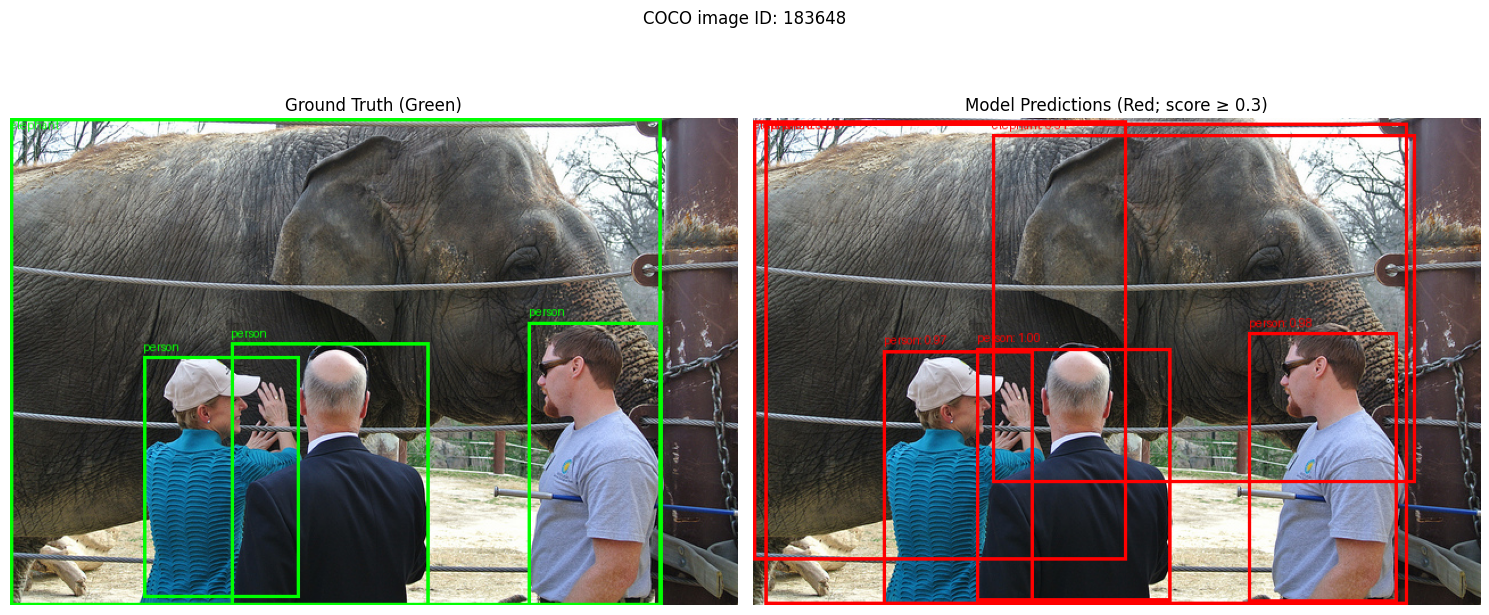

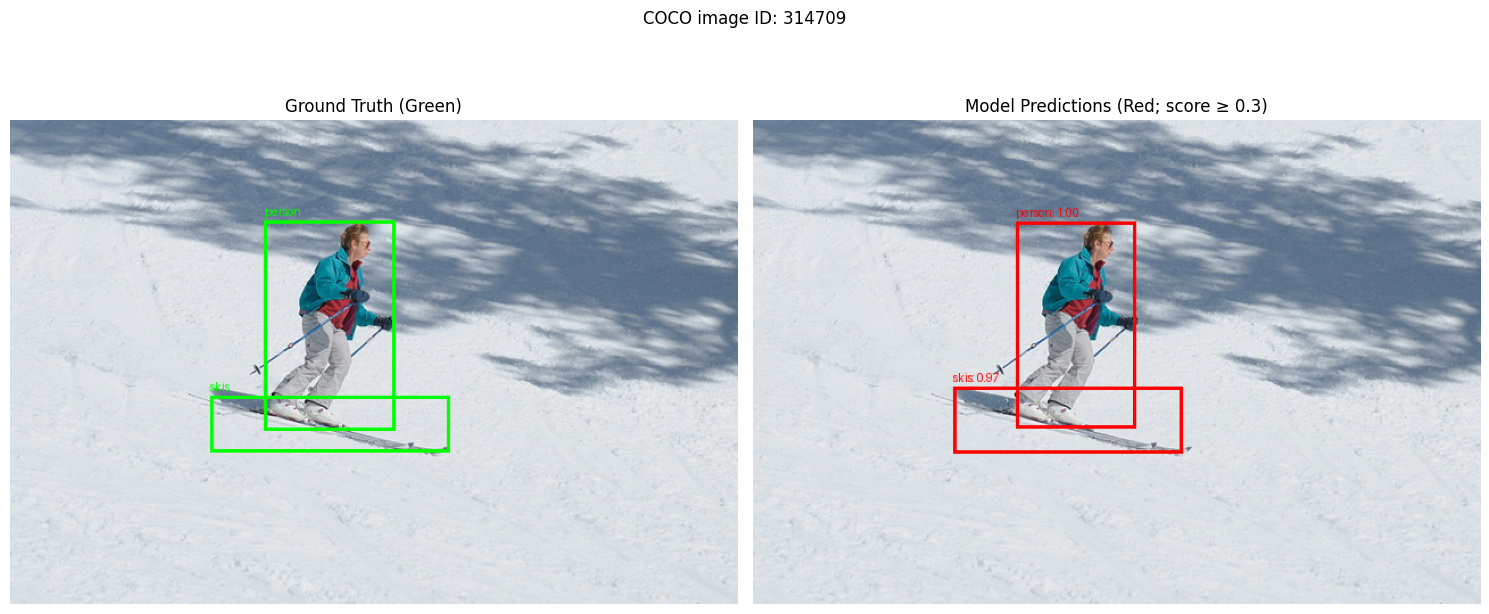

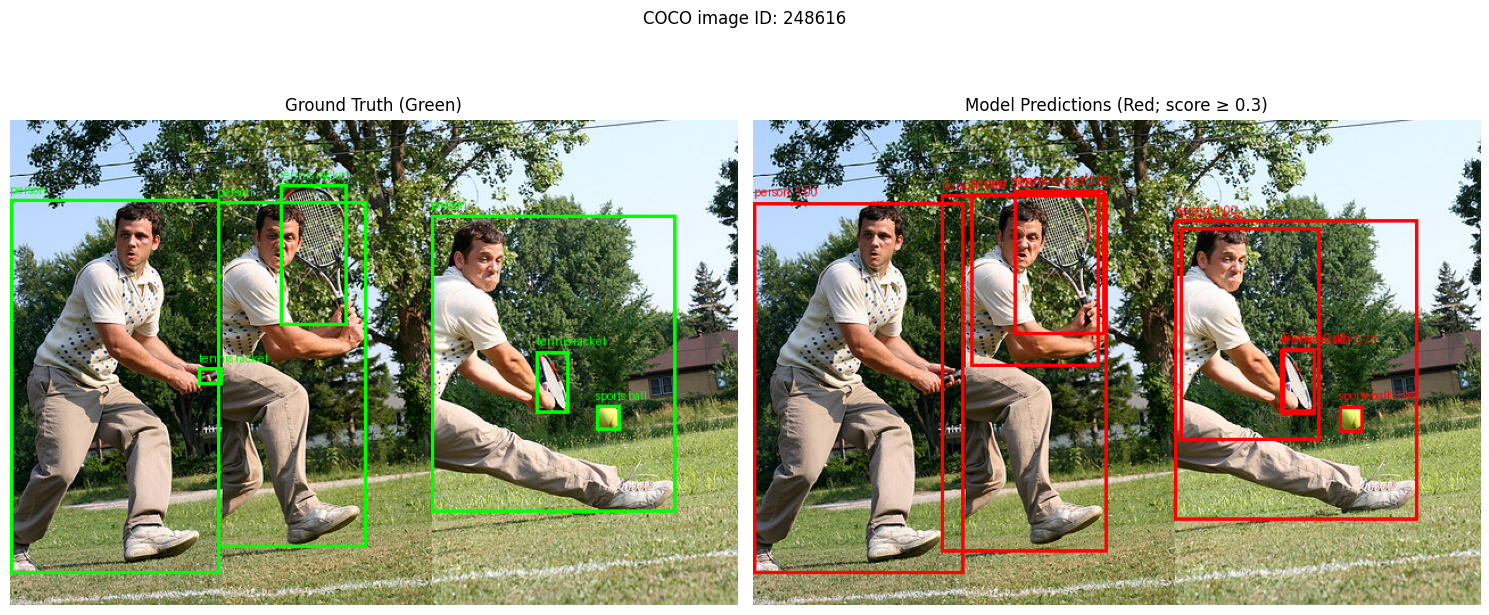

In [31]:
#visually seeing the IoUs and predictions
import os
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

# Use COCO's official category IDs and class names
categories = coco_gt.loadCats(coco_gt.getCatIds())
category_names = {cat["id"]: cat["name"] for cat in categories}

def show_eval_image(image_id, score_threshold=0.30):
    info = coco_gt.loadImgs([image_id])[0]
    image_path = os.path.join(image_dir, info["file_name"])

    image = Image.open(image_path).convert("RGB")
    ground_truth_image = image.copy()
    prediction_image = image.copy()

    gt_draw = ImageDraw.Draw(ground_truth_image)
    pred_draw = ImageDraw.Draw(prediction_image)

    # Draw ground-truth boxes in GREEN
    gt_annotations = coco_gt.loadAnns(
        coco_gt.getAnnIds(imgIds=[image_id])
    )

    for ann in gt_annotations:
        x, y, w, h = ann["bbox"]
        name = category_names.get(ann["category_id"], "Unknown")

        gt_draw.rectangle(
            [x, y, x + w, y + h],
            outline="lime",
            width=3
        )
        gt_draw.text((x, max(0, y - 15)), name, fill="lime")

    # Draw model predictions in RED
    image_predictions = [
        p for p in predictions
        if p["image_id"] == image_id
        and p["score"] >= score_threshold
    ]

    for pred in image_predictions:
        x, y, w, h = pred["bbox"]
        name = category_names.get(pred["category_id"], "Unknown")
        label = f"{name}: {pred['score']:.2f}"

        pred_draw.rectangle(
            [x, y, x + w, y + h],
            outline="red",
            width=3
        )
        pred_draw.text((x, max(0, y - 15)), label, fill="red")

    # Display both images side by side
    fig, axes = plt.subplots(1, 2, figsize=(15, 7))

    axes[0].imshow(ground_truth_image)
    axes[0].set_title("Ground Truth (Green)")
    axes[0].axis("off")

    axes[1].imshow(prediction_image)
    axes[1].set_title(
        f"Model Predictions (Red; score ≥ {score_threshold})"
    )
    axes[1].axis("off")

    plt.suptitle(f"COCO image ID: {image_id}")
    plt.tight_layout()
    plt.show()

# Display the first three evaluated images
for image_id in image_ids[:3]:
    show_eval_image(image_id)